## EJERCICO 1- SISTEMAS DE CLASIFICACION DE RESIDUOS

ENTRENAR UN MODELO CON DIFERENTES CLASES
VIDRIO,PAPEL,CARTON,PLASTICO

##PASO 1 INSTALAR LAS DEPENDENCIAS

In [2]:
!pip install tensorflow numpy pillow matplotlib

In [3]:
!pip install kagglehub

In [4]:
from kagglehub import dataset_download
dataset_path=dataset_download("saumyamohandas/garbage-classification-image-dataset")
print("Ruta de acceso es:",dataset_path)

Using Colab cache for faster access to the 'garbage-classification-image-dataset' dataset.
Ruta de acceso es: /kaggle/input/garbage-classification-image-dataset


In [5]:
import os
for folder in os.listdir(dataset_path):
  print(folder)

dataset


In [7]:
import tensorflow as tf
train_ds=tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    image_size=(224,224),
    batch_size=132

)
class_names=train_ds.class_names
print(class_names)

Found 2972 files belonging to 1 classes.
['dataset']


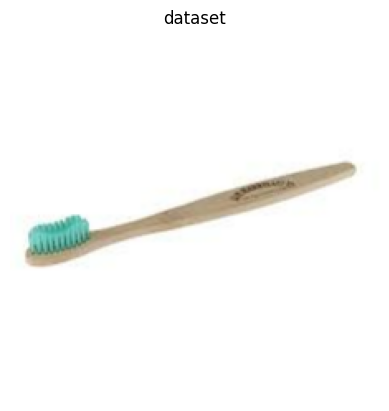

In [9]:
import matplotlib.pyplot as plt
for images, labels in train_ds.take(1):
  plt.imshow(images[0].numpy().astype("uint8"))
  plt.title(class_names[labels[0]])
  plt.axis("off")

In [10]:
import json
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from PIL import Image

In [16]:
IMG_SIZE=(224,224)
BATCH_SIZE=59
SEED=100

In [12]:
DATA_DIR=os.path.join(dataset_path, "dataset")

## SEPARAR LOS DATOS DE ENTRENAMIENTO Y LOS DE PRUEBA

In [14]:
train_data_path=os.path.join(DATA_DIR, "Training")
val_data_path=os.path.join(DATA_DIR, "Testing")


In [17]:
train_ds=tf.keras.preprocessing.image_dataset_from_directory(
    train_data_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=SEED
)
Val_ds=tf.keras.preprocessing.image_dataset_from_directory(
    val_data_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=SEED
)
class_names=train_ds.class_names
print("CLASES DETECTADAS",class_names)

Found 2508 files belonging to 6 classes.
Found 464 files belonging to 6 classes.
CLASES DETECTADAS ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


## VER ALGUNAS IMAGENES

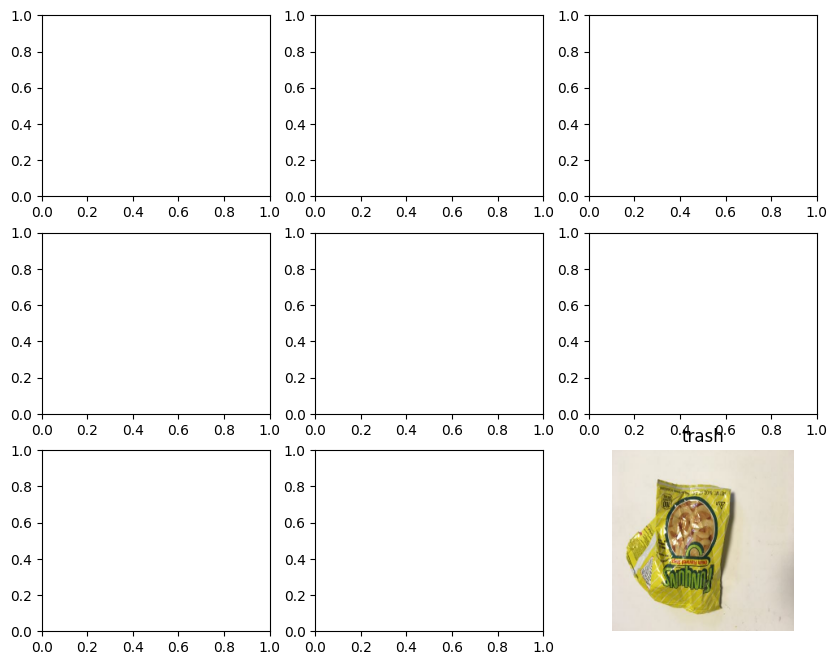

In [19]:
plt.figure(figsize=(10,8))
for images, labels in train_ds.take(1):
  for i in range(9):
    ax=plt.subplot(3,3,i+1)
  plt.imshow(images[i].numpy().astype("uint8"))
  plt.title(class_names[labels[i]])
  plt.axis("off")
  plt.show()

## PREPARAR EL DATASET

In [21]:
AUTOTUNE=tf.data.AUTOTUNE

preprocess_input=tf.keras.applications.mobilenet_v2.preprocess_input

train_ds=train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
Val_ds=Val_ds.cache().prefetch(buffer_size=AUTOTUNE)


##CARGAR EL MODELO MOBILENETV2

In [31]:
base_model=tf.keras.applications.MobileNetV2(input_shape=(224,224,3),
                                                  include_top=False,
                                              weights="imagenet")
base_model.trainable=False
inputs=tf.keras.Input(shape=(224,224,3))
x=preprocess_input(inputs)
x=base_model(x, training=False)
x=tf.keras.layers.GlobalAveragePooling2D()(x)
outputs=tf.keras.layers.Dense(len(class_names),activation="softmax")(x)

model=tf.keras.Model(inputs, outputs)

model.compile(optimizer="adam",
            loss=tf.keras.losses.SparseCategoricalCrossentropy(),
metrics=["accuracy"])

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

##ENTRENAR

In [34]:
EPOCHS=2
callbacks=[
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
        )

]

history=model.fit(
    train_ds,
    validation_data=Val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/2
43/43 ━━━━━━━━━━━━━━━━━━━━ 126s 3s/step - accuracy: 0.8429 - loss: 0.4745 - val_accuracy: 0.7759 - val_loss: 0.6222
Epoch 2/2
43/43 ━━━━━━━━━━━━━━━━━━━━ 122s 3s/step - accuracy: 0.8672 - loss: 0.4116 - val_accuracy: 0.7845 - val_loss: 0.6000


##GUARDAR EL MODELO

In [36]:
OUTPUT_DIR=Path("modelo_reciclaje_mobilenet")
OUTPUT_DIR.mkdir(exist_ok=True)
model.save(OUTPUT_DIR/"waste_mobilenet.h5")
model.save(OUTPUT_DIR/"waste_mobilenet.keras")

with open(OUTPUT_DIR/"history.json", "w", encoding="utf8") as f:
  json.dump(class_names, f, indent=2)

  print("modelo guardado en :", OUTPUT_DIR /"waste_mobilenet.h5")
  print("modelo guardado en :", OUTPUT_DIR /"waste_mobilenet.keras")
  print("modelo guardado en :", OUTPUT_DIR /"history.json")

modelo guardado en : modelo_reciclaje_mobilenet/waste_mobilenet.h5
modelo guardado en : modelo_reciclaje_mobilenet/waste_mobilenet.keras
modelo guardado en : modelo_reciclaje_mobilenet/history.json


##probar nuestro modelo pre-entrenado con una imagen que nunca haya visto

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step


(np.float64(-0.5), np.float64(319.5), np.float64(239.5), np.float64(-0.5))

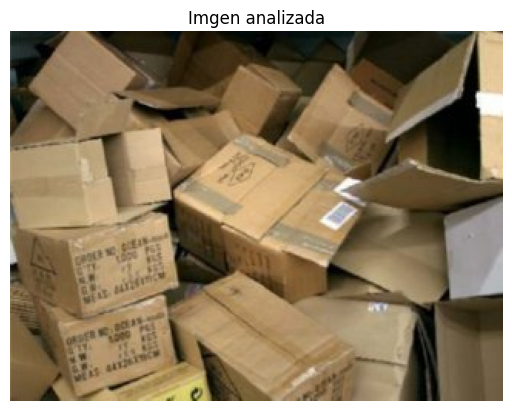

In [46]:
LABELS_ES={
    "carboard":"CARTON",
    "paper":"PAPEL",
    "plastic":"PLASTICO",
    "glass":"VIDRIO",
    "metal":"METAL",
    "trash":"DESCARTE",
}

def predict_image(image_path_param):
  img=Image.open(image_path_param).resize((224,224))
  img_array=tf.keras.preprocessing.image.img_to_array(img)
  img_array=tf.expand_dims(img_array, 0)
  predictions=model.predict(img_array)
  score=tf.nn.softmax(predictions[0])
  return LABELS_ES(class_names[np.argmax(score)])

nueva_imagen="CARTONES.jpg"
predict_image(nueva_imagen)
plt.imshow(Imagen.open(nueva_imagen))
plt.title("Imgen analizada")
plt.axis("off")
